<a href="https://colab.research.google.com/github/Symon-CNA/CNA/blob/main/Metodo_de_Miller.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

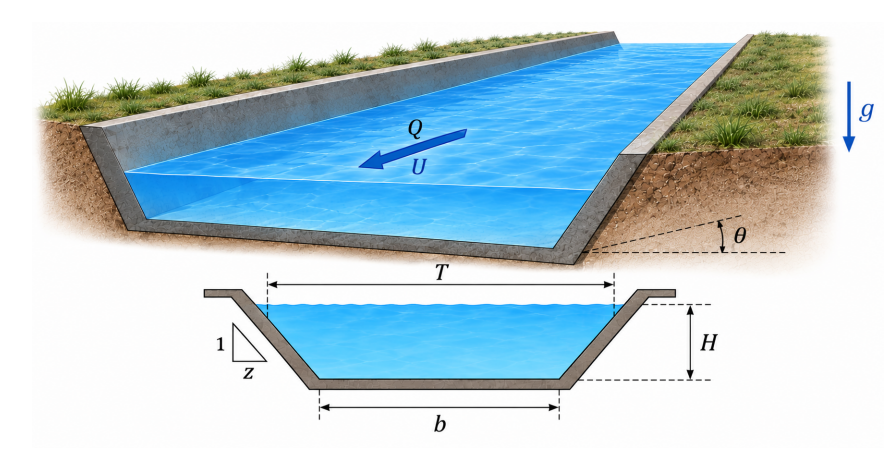

k    H0        H1        H2        H3 (Nova)   f(H3)          Erro        
1    0.50000   1.00000   1.50000   1.201594    2.8287e+02     2.9841e-01  
2    1.00000   1.50000   1.20159   1.185836    1.3379e+02     1.5758e-02  
3    1.50000   1.20159   1.18584   1.179611    7.1928e+01     1.9972e-02  
4    1.20159   1.18584   1.17961-0.01898j1.171327    2.4884e+00     2.0932e-02  
5    1.18584   1.17961-0.01898j1.17133+0.00025j1.171050    4.1254e-02     3.7662e-04  
6    1.17961-0.01898j1.17133+0.00025j1.17105-0.00001j1.171046    2.2600e-03     1.1371e-05  
7    1.17133+0.00025j1.17105-0.00001j1.17105+0.00000j1.171045    -5.3108e-08    3.5393e-07  
8    1.17105-0.00001j1.17105+0.00000j1.17105-0.00000j1.171045    2.7057e-11     1.9684e-10  

---> Resultados para Q = 20 m³/s <---
Profundidade Crítica (Hc): 1.171045 m
Número de iterações: 8
Número de Froude ao quadrado (Fr²): 1.000000 (Esperado ~ 1.0)
Fisicamente admissível? Sim


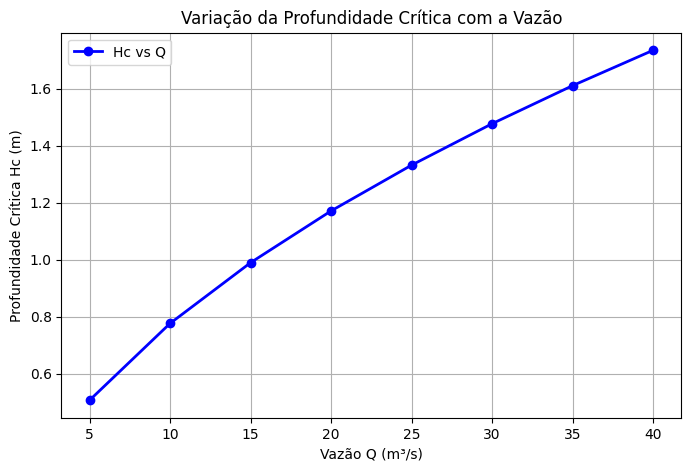

In [ ]:
from IPython.lib.display import html_escape
import numpy as np
import matplotlib.pyplot as plt

# Parametros
b = 4
z = 1.5
g = 9.81
q = 20

def f(H, Q, b=4.0, z=1.5, g=9.81):
  return (g*z**3*H**6) +(3*b*g*(z**2)*H**5) + (3*g*(b**2)*z*H**4) + (g*(b**3)*H**3) - (2*(Q**2)*z*H) - ((Q**2)*b)


# Implementação do Método de Müller
def muller(Q, H0, H1, H2, tol=1e-8, max_iter=100, verbose=False):
    if verbose:
        print(
            f"{'k':<5}{'H0':<10}{'H1':<10}{'H2':<10}{'H3 (Nova)':<12}{'f(H3)':<15}{'Erro':<12}"
        )

    for k in range(1, max_iter + 1):
        f0 = f(H0, Q)
        f1 = f(H1, Q)
        f2 = f(H2, Q)

        h0 = H1 - H0
        h1 = H2 - H1

        delta0 = (f1 - f0) / h0
        delta1 = (f2 - f1) / h1

        a = (delta1 - delta0) / h1 + h0
        bM = (a*h1) + delta1
        c = f2


        # Discriminante e escolha do denominador para evitar cancelamento numérico
        D = (bM**2 - 4*a*c)**0.5
        if abs(bM + D) > abs(bM - D):
          E = bM + D
        else:
          E = bM - D

        deltah = (-2*c) / E
        H3 = H2 + deltah
        erro = abs(H3 - H2)

        if verbose:
            print(
                f"{k:<5}{H0:<10.5f}{H1:<10.5f}{H2:<10.5f}{H3.real:<12.6f}{f(H3, Q).real:<15.4e}{erro.real:<12.4e}"
            )
        if erro > tol:
          H0 = H1
          H1 = H2
          H2 = H3
        else:
          return H3.real, k
    raise ValueError("O método não convergiu no número máximo de iterações.")

# --- Teste Inicial para Q = 20 m³/s (Partes 3 e 4) ---
H_critico, iters = muller(q, H0=0.5, H1=1.0, H2=1.5, verbose=True)

# Verificação Física
Ac = b*H_critico + z*(H_critico**2)
Tc = b + 2*z*H_critico
Fr2 = ((q**2)*Tc) / (g*Ac**3)


print(f"\n---> Resultados para Q = 20 m³/s <---")
print(f"Profundidade Crítica (Hc): {H_critico:.6f} m")
print(f"Número de iterações: {iters}")
print(f"Número de Froude ao quadrado (Fr²): {Fr2:.6f} (Esperado ~ 1.0)")
print(f"Fisicamente admissível? {'Sim' if H_critico > 0 else 'Não'}")

# --- Parte 5: Varredura para diferentes vazões ---
vazoes = [5, 10, 15, 20, 25, 30, 35, 40]
hc_valores = []

for z in vazoes:
    hc, _ = muller(z, H0=0.5, H1=1.0, H2=1.5)
    hc_valores.append(hc)

# Gráfico Hc x Q
plt.figure(figsize=(8, 5))
plt.plot(vazoes, hc_valores, "o-b", linewidth=2, label="Hc vs Q")
plt.title("Variação da Profundidade Crítica com a Vazão")
plt.xlabel("Vazão Q (m³/s)")
plt.ylabel("Profundidade Crítica Hc (m)")
plt.grid(True)
plt.legend()
plt.show()

**Questões para discussão**

**a)** Qual foi a profundidade crítica encontrada para Q = 20 m3/s?

**b)** A solução encontrada satisfaz numericamente a condição F r ≈ 1?

**c)** Por que a equação obtida para o canal trapezoidal resulta em um polinômio de sexta
ordem?

**d)** Por que nem todas as raízes matemáticas desse polinômio representam soluções
fisicamente possíveis?

**e)** O que acontece com a profundidade crítica quando a vazão aumenta? O comporta-
mento observado no gráfico é fisicamente coerente?

**f)** Repita o cálculo para Q = 20 m3/s utilizando três aproximações iniciais diferentes.
O método converge para a mesma raiz?

**g)** Qual é a função dos três pontos utilizados pelo método de Müller e qual é a diferença
fundamental entre essa aproximação e a reta utilizada pelo método da secante?

**h)** Por que a escolha do denominador de maior módulo na expressão de Müller é nu-
mericamente conveniente?